# Analyse des retards ferroviaires de l'ONCF — Dataset synthétique

**Objectif :** comprendre, contrôler et nettoyer un jeu de données synthétique de 50 000 circulations, puis préparer les données pour l'analyse exploratoire et Power BI.

> **Important :** les observations, retards, causes et indicateurs de ce fichier sont synthétiques. Ils ne représentent pas les performances opérationnelles réelles de l'ONCF.

## 1. Configuration de l'environnement

Importation des bibliothèques utilisées dans le projet et configuration de l'affichage.

In [ ]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Environnement prêt.")

Environnement prêt.


## 2. Connexion à Google Drive et préparation des dossiers

Google Drive permet de conserver les fichiers du projet entre les sessions Colab.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

project_path = "/content/drive/MyDrive/ONCF_DATA_ANALYSIS"

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "visualizations",
    "powerbi",
    "documentation"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Dossiers du projet prêts :", project_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dossiers du projet prêts : /content/drive/MyDrive/ONCF_DATA_ANALYSIS


## 3. Chargement du dataset

Le fichier CSV doit être placé dans `data/raw`. Si le fichier n'est pas encore dans ce dossier, téléverse-le dans Colab et copie-le dans le dossier attendu.

In [ ]:
raw_file = os.path.join(
    project_path,
    "data",
    "raw",
    "circulations_retards_synthetiques_50000.csv"
)

if not os.path.exists(raw_file):
    from google.colab import files
    uploaded = files.upload()

    expected_name = "circulations_retards_synthetiques_50000.csv"
    if expected_name not in uploaded:
        raise FileNotFoundError(
            f"Téléverse le fichier nommé exactement : {expected_name}"
        )

    shutil.copy(expected_name, raw_file)

df = pd.read_csv(raw_file)

print("Dataset chargé.")
print("Dimensions :", df.shape)
display(df.head())

Dataset chargé.
Dimensions : (50000, 22)


,run_id,service_date,service_id,route_id,service_type,service_category,origin_station,destination_station,scheduled_departure_local,scheduled_duration_min,actual_arrival_delay_min_synthetic,delay_class_synthetic,is_on_time_5min_synthetic,is_delayed_15min_synthetic,primary_delay_cause_synthetic,peak_period_synthetic,weekday,month,year,season,data_status,data_warning
0,RUN006302,2024-01-01,ATLAS_CAS_FES_003,ATLAS_CAS_FES,Al Atlas,Grandes lignes,Casa-Voyageurs,Fès,09:34,240,6,Faible_6_15,0,0,Exploitation / circulation,0,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
1,RUN047076,2024-01-01,ATLAS_CAS_FES_003,ATLAS_CAS_FES,Al Atlas,Grandes lignes,Casa-Voyageurs,Fès,09:34,240,3,Ponctuel_0_5,1,0,Aucun retard,0,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
2,RUN034161,2024-01-01,ATLAS_CAS_FES_005,ATLAS_CAS_FES,Al Atlas,Grandes lignes,Casa-Voyageurs,Fès,13:08,240,0,Ponctuel_0_5,1,0,Aucun retard,0,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
3,RUN020231,2024-01-01,ATLAS_CAS_FES_006,ATLAS_CAS_FES,Al Atlas,Grandes lignes,Casa-Voyageurs,Fès,15:25,240,2,Ponctuel_0_5,1,0,Aucun retard,0,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
4,RUN042067,2024-01-01,ATLAS_CAS_FES_006,ATLAS_CAS_FES,Al Atlas,Grandes lignes,Casa-Voyageurs,Fès,15:25,240,22,Modere_16_30,0,1,Incident technique,0,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...


## 4. Compréhension initiale des données (Data Understanding)

### 4.1. Structure et types des colonnes

Cette étape permet d'identifier le nombre d'observations, les variables et leurs types initiaux.

In [ ]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

df.info()

Nombre de lignes : 50000
Nombre de colonnes : 22
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   run_id                              50000 non-null  object
 1   service_date                        50000 non-null  object
 2   service_id                          50000 non-null  object
 3   route_id                            50000 non-null  object
 4   service_type                        50000 non-null  object
 5   service_category                    50000 non-null  object
 6   origin_station                      50000 non-null  object
 7   destination_station                 50000 non-null  object
 8   scheduled_departure_local           50000 non-null  object
 9   scheduled_duration_min              50000 non-null  int64 
 10  actual_arrival_delay_min_synthetic  50000 non-null  int64 
 11  delay

### 4.2. Statistiques descriptives

Les statistiques permettent de résumer les variables numériques et catégorielles.

In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
run_id,50000,50000,RUN006302,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_date,50000,731,2025-07-29,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_id,50000,100,BOR_CAS_TNG_004,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
route_id,50000,12,TNR_CAS_KEN,9006,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_type,50000,3,Al Atlas,24049,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_category,50000,3,Grandes lignes,24049,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_station,50000,7,Casa-Voyageurs,15964,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_station,50000,9,Casa-Voyageurs,10028,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scheduled_departure_local,50000,18,09:34,6140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scheduled_duration_min,50000.0,NaN,NaN,NaN,185.4624,102.634969,100.0,100.0,130.0,240.0,420.0


### 4.3. Valeurs manquantes

On mesure le nombre de valeurs manquantes par colonne avant toute transformation.

In [ ]:
missing_initial = df.isna().sum().sort_values(ascending=False)
display(missing_initial[missing_initial > 0])
print("Total des valeurs manquantes :", int(missing_initial.sum()))

,0


Total des valeurs manquantes : 0


### 4.4. Doublons et unicité des identifiants

On vérifie les doublons de lignes et l'unicité de `run_id`. Aucune ligne n'est supprimée automatiquement.

In [ ]:
print("Lignes dupliquées :", int(df.duplicated().sum()))
print("run_id dupliqués :", int(df["run_id"].duplicated().sum()))

Lignes dupliquées : 0
run_id dupliqués : 0


### 4.5. Répartition des principales variables catégorielles

In [ ]:
initial_categorical_columns = [
    "service_type",
    "service_category",
    "delay_class_synthetic",
    "primary_delay_cause_synthetic",
    "season"
]

for col in initial_categorical_columns:
    if col in df.columns:
        print(f"\\n--- {col} ---")
        display(df[col].value_counts(dropna=False))

\n--- service_type ---


,count
service_type,
Al Atlas,24049
TNR,17988
Al Boraq,7963


\n--- service_category ---


,count
service_category,
Grandes lignes,24049
Navette régionale,17988
Grande vitesse,7963


\n--- delay_class_synthetic ---


,count
delay_class_synthetic,
Ponctuel_0_5,26917
Faible_6_15,14681
Modere_16_30,5935
Important_31_60,2261
Severe_60_plus,206


\n--- primary_delay_cause_synthetic ---


,count
primary_delay_cause_synthetic,
Aucun retard,29002
Exploitation / circulation,7579
Affluence voyageurs,4028
Incident technique,3957
Météo,2902
Travaux / infrastructure,2532


\n--- season ---


,count
season,
Été,12648
Printemps,12619
Hiver,12454
Automne,12279


### 4.6. Vérification initiale des dates

La date de service est convertie au format datetime afin de vérifier la période couverte et la cohérence des champs année, mois et jour de semaine.

In [ ]:
df["service_date"] = pd.to_datetime(df["service_date"], errors="coerce")

print("Date minimale :", df["service_date"].min())
print("Date maximale :", df["service_date"].max())
print("Dates invalides :", int(df["service_date"].isna().sum()))

print(
    "Année incorrecte :",
    int((df["year"] != df["service_date"].dt.year).sum())
)
print(
    "Mois incorrect :",
    int((df["month"] != df["service_date"].dt.month).sum())
)
print(
    "Jour de semaine incorrect :",
    int((df["weekday"] != df["service_date"].dt.dayofweek).sum())
)

Date minimale : 2024-01-01 00:00:00
Date maximale : 2025-12-31 00:00:00
Dates invalides : 0
Année incorrecte : 0
Mois incorrect : 0
Jour de semaine incorrect : 0


### 4.7. Vérification initiale des indicateurs et des classes de retard

Les règles de contrôle sont celles définies dans le jeu de données :
- ponctuel : retard inférieur ou égal à 5 minutes ;
- retard supérieur à 15 minutes : strictement supérieur à 15 minutes ;
- classes : 0–5, 6–15, 16–30, 31–60 et plus de 60 minutes.

In [ ]:
delay_initial = df["actual_arrival_delay_min_synthetic"]

on_time_errors = (
    df["is_on_time_5min_synthetic"] != (delay_initial <= 5).astype(int)
).sum()

delayed_errors = (
    df["is_delayed_15min_synthetic"] != (delay_initial > 15).astype(int)
).sum()

conditions_initial = [
    delay_initial.between(0, 5),
    delay_initial.between(6, 15),
    delay_initial.between(16, 30),
    delay_initial.between(31, 60),
    delay_initial > 60
]
classes_initial = [
    "Ponctuel_0_5",
    "Faible_6_15",
    "Modere_16_30",
    "Important_31_60",
    "Severe_60_plus"
]
expected_initial = np.select(
    conditions_initial, classes_initial, default="Invalide"
)
class_errors = (
    df["delay_class_synthetic"].astype(str) != expected_initial
).sum()

print("Erreurs indicateur ponctualité :", int(on_time_errors))
print("Erreurs indicateur retard > 15 min :", int(delayed_errors))
print("Classes de retard incorrectes :", int(class_errors))

print("\\nRépartition des classes :")
display(df["delay_class_synthetic"].value_counts())

Erreurs indicateur ponctualité : 0
Erreurs indicateur retard > 15 min : 0
Classes de retard incorrectes : 0
\nRépartition des classes :


,count
delay_class_synthetic,
Ponctuel_0_5,26917
Faible_6_15,14681
Modere_16_30,5935
Important_31_60,2261
Severe_60_plus,206


## 5. Nettoyage des données (Data Cleaning)

On conserve une copie du dataset initial et on effectue les transformations sur `df_clean`. Les contrôles déjà réussis dans la phase précédente ne sont pas répétés inutilement.

In [ ]:
df_raw = df.copy(deep=True)
df_clean = df.copy(deep=True)

print("Copie de travail créée.")
print("Dataset brut :", df_raw.shape)
print("Dataset de travail :", df_clean.shape)

Copie de travail créée.
Dataset brut : (50000, 22)
Dataset de travail : (50000, 22)


### 5.1. Conversion et vérification des types

- `service_date` devient une date ;
- `scheduled_departure_local` est interprétée au format heure `HH:MM` ;
- les indicateurs binaires restent codés en 0/1 (`int8`) ;
- les variables quantitatives sont converties en types numériques.

In [ ]:
# Date de circulation
df_clean["service_date"] = pd.to_datetime(
    df_clean["service_date"], errors="coerce"
)

# Heure de départ : parsing puis conservation sous forme d'heure
parsed_time = pd.to_datetime(
    df_clean["scheduled_departure_local"].astype("string").str.strip(),
    format="%H:%M",
    errors="coerce"
)
df_clean["scheduled_departure_local"] = parsed_time.dt.time

# Variables numériques
numeric_columns = [
    "scheduled_duration_min",
    "actual_arrival_delay_min_synthetic",
    "weekday",
    "month",
    "year"
]
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Indicateurs binaires
binary_columns = [
    "is_on_time_5min_synthetic",
    "is_delayed_15min_synthetic",
    "peak_period_synthetic"
]
for col in binary_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

print("Dates invalides :", int(df_clean["service_date"].isna().sum()))
print("Heures invalides :", int(pd.isna(df_clean["scheduled_departure_local"]).sum()))
display(df_clean.dtypes.to_frame(name="Type"))

Dates invalides : 0
Heures invalides : 0


,Type
run_id,object
service_date,datetime64[ns]
service_id,object
route_id,object
service_type,object
service_category,object
origin_station,object
destination_station,object
scheduled_departure_local,object
scheduled_duration_min,int64


### 5.2. Nettoyage des colonnes textuelles

On supprime les espaces au début et à la fin, puis on remplace les suites d'espaces par un seul espace. On ne change pas arbitrairement les noms des catégories.

In [ ]:
text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for col in text_columns:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\\s+", " ", regex=True)
    )

print("Nettoyage des espaces terminé.")

empty_strings = {}
for col in text_columns:
    count_empty = int((df_clean[col] == "").sum())
    if count_empty:
        empty_strings[col] = count_empty

print("Chaînes vides par colonne :", empty_strings if empty_strings else "Aucune")

Nettoyage des espaces terminé.
Chaînes vides par colonne : Aucune


### 5.3. Contrôle des valeurs manquantes après conversion

Les conversions peuvent transformer des valeurs non interprétables en valeurs manquantes (`NaN` ou `NaT`). On les recense avant de décider d'une éventuelle correction.

In [ ]:
missing_after_conversion = df_clean.isna().sum().sort_values(ascending=False)
display(missing_after_conversion[missing_after_conversion > 0])
print("Total des valeurs manquantes :", int(missing_after_conversion.sum()))

,0


Total des valeurs manquantes : 0


### 5.4. Contrôle des doublons

On vérifie les doublons après nettoyage textuel. On ne supprime pas de lignes sans avoir établi qu'il s'agit réellement de doublons à éliminer.

In [ ]:
print("Lignes dupliquées :", int(df_clean.duplicated().sum()))
print("run_id dupliqués :", int(df_clean["run_id"].duplicated().sum()))

Lignes dupliquées : 0
run_id dupliqués : 0


### 5.5. Contrôle des valeurs numériques et des domaines autorisés

On recherche les durées nulles ou négatives, les retards négatifs, ainsi que les valeurs hors des domaines attendus pour le jour, le mois et l'année.

In [ ]:
checks_numeric = {
    "Durées nulles ou négatives": int((df_clean["scheduled_duration_min"] <= 0).sum()),
    "Retards négatifs": int((df_clean["actual_arrival_delay_min_synthetic"] < 0).sum()),
    "Weekday hors 0-6": int((~df_clean["weekday"].between(0, 6)).sum()),
    "Month hors 1-12": int((~df_clean["month"].between(1, 12)).sum()),
    "Year hors 2024-2025": int((~df_clean["year"].between(2024, 2025)).sum())
}
display(pd.Series(checks_numeric, name="Nombre d'anomalies").to_frame())

,Nombre d'anomalies
Durées nulles ou négatives,0
Retards négatifs,0
Weekday hors 0-6,0
Month hors 1-12,0
Year hors 2024-2025,0


### 5.6. Contrôle des indicateurs binaires

Chaque indicateur doit contenir uniquement 0 ou 1. On vérifie aussi les valeurs manquantes.

In [ ]:
for col in binary_columns:
    values = sorted(df_clean[col].dropna().unique().tolist())
    invalid_count = int((~df_clean[col].isin([0, 1])).sum())
    print(f"{col} : valeurs={values}, manquantes={int(df_clean[col].isna().sum())}, invalides={invalid_count}")

is_on_time_5min_synthetic : valeurs=[0, 1], manquantes=0, invalides=0
is_delayed_15min_synthetic : valeurs=[0, 1], manquantes=0, invalides=0
peak_period_synthetic : valeurs=[0, 1], manquantes=0, invalides=0


### 5.7. Nouvelle vérification des règles de ponctualité et des classes

On recalcule les indicateurs attendus à partir du retard, puis on compare avec les colonnes existantes. Cette étape sert de contrôle final de cohérence.

In [ ]:
delay = df_clean["actual_arrival_delay_min_synthetic"]

on_time_errors_clean = int((
    df_clean["is_on_time_5min_synthetic"] != (delay <= 5).astype("int8")
).sum())

delayed_errors_clean = int((
    df_clean["is_delayed_15min_synthetic"] != (delay > 15).astype("int8")
).sum())

conditions = [
    delay.between(0, 5),
    delay.between(6, 15),
    delay.between(16, 30),
    delay.between(31, 60),
    delay > 60
]
classes = [
    "Ponctuel_0_5",
    "Faible_6_15",
    "Modere_16_30",
    "Important_31_60",
    "Severe_60_plus"
]
expected_class = np.select(conditions, classes, default="Invalide")

class_errors_clean = int((
    df_clean["delay_class_synthetic"].astype(str) != expected_class
).sum())

print("Erreurs indicateur ponctualité :", on_time_errors_clean)
print("Erreurs indicateur retard > 15 min :", delayed_errors_clean)
print("Classes incorrectes :", class_errors_clean)

Erreurs indicateur ponctualité : 0
Erreurs indicateur retard > 15 min : 0
Classes incorrectes : 0


### 5.8. Contrôle de la cohérence des dates

On confirme que les colonnes année, mois et jour de semaine correspondent à `service_date`. La convention `dayofweek` de pandas est lundi = 0 et dimanche = 6.

In [ ]:
date_checks = {
    "Années incorrectes": int((df_clean["year"] != df_clean["service_date"].dt.year).sum()),
    "Mois incorrects": int((df_clean["month"] != df_clean["service_date"].dt.month).sum()),
    "Jours de semaine incorrects": int((df_clean["weekday"] != df_clean["service_date"].dt.dayofweek).sum())
}
display(pd.Series(date_checks, name="Nombre d'erreurs").to_frame())

,Nombre d'erreurs
Années incorrectes,0
Mois incorrects,0
Jours de semaine incorrects,0


### 5.9. Analyse des valeurs extrêmes

Les retards élevés sont signalés et examinés, mais ne sont pas supprimés automatiquement. Une valeur extrême n'est pas nécessairement une erreur, particulièrement dans un dataset synthétique conçu pour représenter plusieurs niveaux de retard.

,Statistiques
count,50000.000000
mean,8.662860
std,10.518865
min,0.000000
25%,2.000000
50%,5.000000
75%,11.000000
max,160.000000


Nombre de retards supérieurs à 60 minutes : 206


,run_id,service_date,service_id,route_id,service_type,service_category,origin_station,destination_station,scheduled_departure_local,scheduled_duration_min,actual_arrival_delay_min_synthetic,delay_class_synthetic,is_on_time_5min_synthetic,is_delayed_15min_synthetic,primary_delay_cause_synthetic,peak_period_synthetic,weekday,month,year,season,data_status,data_warning
47,RUN041206,2024-01-01,TNR_CAS_KEN_001,TNR_CAS_KEN,TNR,Navette régionale,Casa-Port,Kénitra,05:00:00,100,78,Severe_60_plus,0,1,Incident technique,0,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
55,RUN027984,2024-01-01,TNR_CAS_KEN_016,TNR_CAS_KEN,TNR,Navette régionale,Casa-Port,Kénitra,17:15:00,100,83,Severe_60_plus,0,1,Incident technique,1,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
514,RUN016519,2024-01-08,ATLAS_CAS_SAFI_005,ATLAS_CAS_SAFI,Al Atlas,Grandes lignes,Casa-Voyageurs,Safi,13:08:00,190,71,Severe_60_plus,0,1,Incident technique,0,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
1009,RUN036413,2024-01-15,TNR_CAS_KEN_002,TNR_CAS_KEN,TNR,Navette régionale,Casa-Port,Kénitra,07:17:00,100,64,Severe_60_plus,0,1,Exploitation / circulation,1,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
1017,RUN021453,2024-01-15,TNR_CAS_KEN_016,TNR_CAS_KEN,TNR,Navette régionale,Casa-Port,Kénitra,17:15:00,100,63,Severe_60_plus,0,1,Incident technique,1,0,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
1154,RUN039505,2024-01-17,TNR_CAS_KEN_017,TNR_CAS_KEN,TNR,Navette régionale,Casa-Port,Kénitra,19:32:00,100,71,Severe_60_plus,0,1,Incident technique,1,2,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
1177,RUN037508,2024-01-17,TNR_KEN_CAS_017,TNR_KEN_CAS,TNR,Navette régionale,Kénitra,Casa-Port,19:32:00,100,61,Severe_60_plus,0,1,Incident technique,1,2,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
1710,RUN006702,2024-01-25,TNR_KEN_CAS_013,TNR_KEN_CAS,TNR,Navette régionale,Kénitra,Casa-Port,11:24:00,100,75,Severe_60_plus,0,1,Exploitation / circulation,0,3,1,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
2309,RUN028870,2024-02-02,TNR_KEN_CAS_003,TNR_KEN_CAS,TNR,Navette régionale,Kénitra,Casa-Port,09:34:00,100,64,Severe_60_plus,0,1,Incident technique,0,4,2,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...
2393,RUN023450,2024-02-04,ATLAS_CAS_SAFI_002,ATLAS_CAS_SAFI,Al Atlas,Grandes lignes,Casa-Voyageurs,Safi,07:17:00,190,95,Severe_60_plus,0,1,Exploitation / circulation,1,6,2,2024,Hiver,SYNTHETIC,Observation simulée; ne décrit pas un retard r...


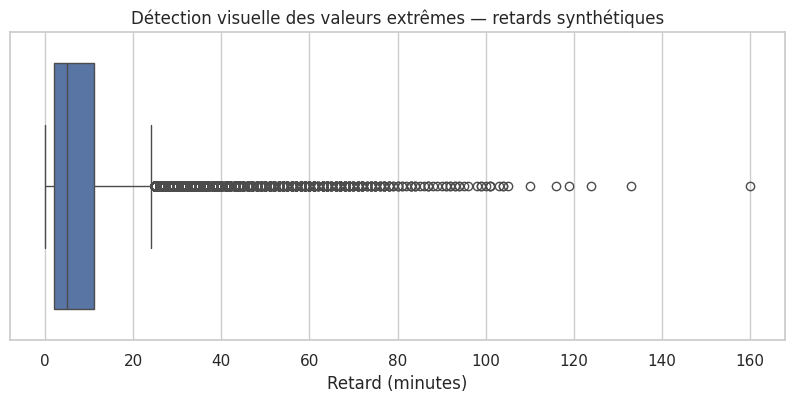

In [ ]:
delay_col = "actual_arrival_delay_min_synthetic"

display(df_clean[delay_col].describe().to_frame(name="Statistiques"))

extreme_delays = df_clean[df_clean[delay_col] > 60]
print("Nombre de retards supérieurs à 60 minutes :", len(extreme_delays))
display(extreme_delays.head(10))

plt.figure(figsize=(10, 4))
sns.boxplot(x=df_clean[delay_col])
plt.title("Détection visuelle des valeurs extrêmes — retards synthétiques")
plt.xlabel("Retard (minutes)")
plt.show()

### 5.10. Contrôle des catégories et de la provenance

On examine les modalités des variables catégorielles. On vérifie en particulier que le statut synthétique et l'avertissement de provenance sont conservés.

In [ ]:
categorical_columns = [
    "service_type",
    "service_category",
    "origin_station",
    "destination_station",
    "delay_class_synthetic",
    "primary_delay_cause_synthetic",
    "season",
    "data_status"
]

for col in categorical_columns:
    print(f"\\n--- {col} ---")
    display(df_clean[col].value_counts(dropna=False))

print("\\nValeurs de data_status :")
display(df_clean["data_status"].value_counts(dropna=False))

print("\\nAvertissements de provenance :")
display(df_clean["data_warning"].value_counts(dropna=False).head())

\n--- service_type ---


,count
service_type,
Al Atlas,24049
TNR,17988
Al Boraq,7963


\n--- service_category ---


,count
service_category,
Grandes lignes,24049
Navette régionale,17988
Grande vitesse,7963


\n--- origin_station ---


,count
origin_station,
Casa-Voyageurs,15964
Casa-Port,9006
Kénitra,8982
Tanger-Ville,7013
Marrakech,3065
Fès,2994
Oujda,2976


... (10 outputs left out)

\nValeurs de data_status :


,count
data_status,
SYNTHETIC,50000


\nAvertissements de provenance :


,count
data_warning,
Observation simulée; ne décrit pas un retard réellement constaté par l'ONCF.,50000


### 5.11. Bilan global du contrôle qualité

Ce tableau récapitule les principaux contrôles réalisés. Si une anomalie est détectée, il faut l'examiner avant l'export plutôt que la corriger automatiquement.

In [ ]:
quality_report = pd.DataFrame({
    "Contrôle": [
        "Nombre de lignes",
        "Nombre de colonnes",
        "Valeurs manquantes",
        "Lignes dupliquées",
        "run_id dupliqués",
        "Durées nulles ou négatives",
        "Retards négatifs",
        "Erreurs indicateur ponctualité",
        "Erreurs indicateur retard > 15 min",
        "Classes incorrectes",
        "Années incorrectes",
        "Mois incorrects",
        "Jours de semaine incorrects"
    ],
    "Résultat": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean.isna().sum().sum()),
        int(df_clean.duplicated().sum()),
        int(df_clean["run_id"].duplicated().sum()),
        int((df_clean["scheduled_duration_min"] <= 0).sum()),
        int((df_clean["actual_arrival_delay_min_synthetic"] < 0).sum()),
        on_time_errors_clean,
        delayed_errors_clean,
        class_errors_clean,
        date_checks["Années incorrectes"],
        date_checks["Mois incorrects"],
        date_checks["Jours de semaine incorrects"]
    ]
})
display(quality_report)

,Contrôle,Résultat
0,Nombre de lignes,50000
1,Nombre de colonnes,22
2,Valeurs manquantes,0
3,Lignes dupliquées,0
4,run_id dupliqués,0
5,Durées nulles ou négatives,0
6,Retards négatifs,0
7,Erreurs indicateur ponctualité,0
8,Erreurs indicateur retard > 15 min,0
9,Classes incorrectes,0


### 5.12. Exportation du dataset nettoyé

On exporte une copie du DataFrame. L'heure de départ est convertie en texte `HH:MM` pour garantir un format CSV simple à importer dans Power BI. Le dataset original reste inchangé.

In [ ]:
df_export = df_clean.copy()

df_export["scheduled_departure_local"] = df_export[
    "scheduled_departure_local"
].apply(
    lambda value: value.strftime("%H:%M")
    if pd.notna(value) and hasattr(value, "strftime")
    else None
)

processed_path = os.path.join(project_path, "data", "processed")
os.makedirs(processed_path, exist_ok=True)

output_file = os.path.join(
    processed_path,
    "oncf_circulations_cleaned_synthetic.csv"
)

df_export.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Export terminé.")
print("Fichier :", output_file)
print("Dimensions exportées :", df_export.shape)
print("Taille (Ko) :", round(os.path.getsize(output_file) / 1024, 2))

Export terminé.
Fichier : /content/drive/MyDrive/ONCF_DATA_ANALYSIS/data/processed/oncf_circulations_cleaned_synthetic.csv
Dimensions exportées : (50000, 22)
Taille (Ko) : 12048.78


### 5.13. Vérification du fichier exporté

On relit le CSV pour s'assurer qu'il est bien enregistré et que ses dimensions sont identiques à celles du DataFrame exporté.

In [ ]:
df_check_export = pd.read_csv(output_file)

print("Dimensions du DataFrame exporté :", df_export.shape)
print("Dimensions après relecture CSV :", df_check_export.shape)
print("Fichier présent :", os.path.exists(output_file))

assert df_check_export.shape == df_export.shape, "Les dimensions ne correspondent pas."
print("Vérification de l'export réussie.")

Dimensions du DataFrame exporté : (50000, 22)
Dimensions après relecture CSV : (50000, 22)
Fichier présent : True
Vérification de l'export réussie.


## 6. Fin de la phase de nettoyage

Le fichier `oncf_circulations_cleaned_synthetic.csv` est maintenant disponible dans `data/processed/`.

**Prochaine phase :** analyse exploratoire (EDA), puis création de variables analytiques et visualisations avant l'importation dans Power BI.

> Ne présente pas les résultats comme des statistiques réelles de l'ONCF : toutes les observations de ce dataset sont synthétiques.

# 7. Exploratory Data Analysis (EDA)

L'analyse exploratoire vise à comprendre la distribution des retards et à identifier les principales tendances présentes dans le jeu de données synthétique.

## 7.1. Analyse des indicateurs globaux

Cette étape présente les indicateurs statistiques généraux relatifs aux circulations, aux retards et à la ponctualité.

In [ ]:
# Variables principales
delay = df_clean["actual_arrival_delay_min_synthetic"]

# Calcul des indicateurs globaux
eda_summary = pd.DataFrame({
    "Indicateur": [
        "Nombre total de circulations",
        "Retard moyen (minutes)",
        "Retard médian (minutes)",
        "Retard maximum (minutes)",
        "Taux de ponctualité (%)",
        "Taux de retards supérieurs à 15 min (%)"
    ],
    "Valeur": [
        len(df_clean),
        round(delay.mean(), 2),
        round(delay.median(), 2),
        delay.max(),
        round(df_clean["is_on_time_5min_synthetic"].mean() * 100, 2),
        round(df_clean["is_delayed_15min_synthetic"].mean() * 100, 2)
    ]
})

display(eda_summary)

,Indicateur,Valeur
0,Nombre total de circulations,50000.00
1,Retard moyen (minutes),8.66
2,Retard médian (minutes),5.00
3,Retard maximum (minutes),160.00
4,Taux de ponctualité (%),53.83
5,Taux de retards supérieurs à 15 min (%),16.80


Interprétation des résultats
- 50 000 circulations : le dataset contient suffisamment d'observations pour réaliser des analyses exploratoires.
- 8,66 minutes de retard moyen : c'est le retard moyen simulé dans le dataset.
- 5 minutes de retard médian : 50 % des circulations ont un retard inférieur ou égal à 5 minutes.
- 160 minutes de retard maximum : c'est le retard le plus élevé enregistré dans les données synthétiques.
- 53,83 % de ponctualité : les circulations ayant un retard inférieur ou égal à 5 minutes représentent 53,83 % du dataset.
- 16,80 % de retards supérieurs à 15 minutes : cette catégorie représente une partie importante des observations.

## 7.2. Distribution des retards

Cette analyse permet d'étudier la répartition des retards et d'identifier les valeurs les plus fréquentes dans le dataset synthétique.

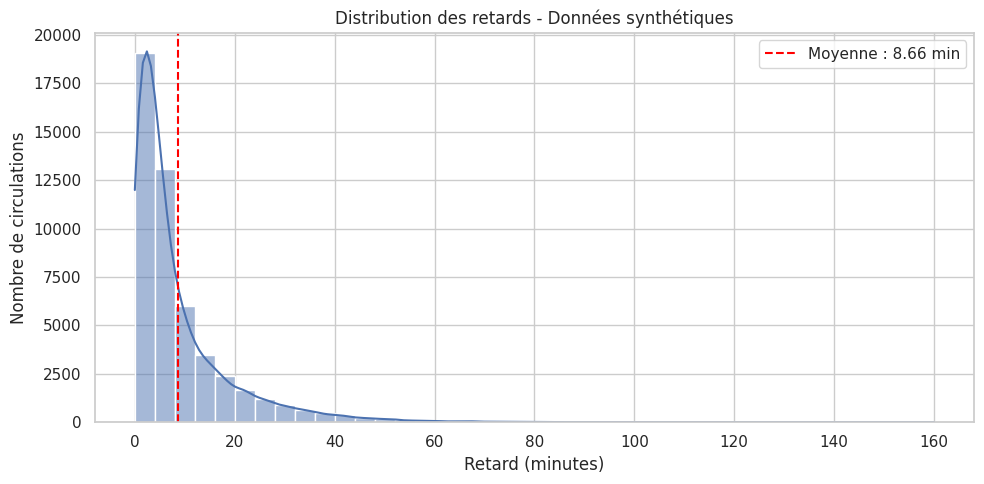

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="actual_arrival_delay_min_synthetic",
    bins=40,
    kde=True
)

plt.axvline(
    delay.mean(),
    color="red",
    linestyle="--",
    label=f"Moyenne : {delay.mean():.2f} min"
)

plt.title("Distribution des retards - Données synthétiques")
plt.xlabel("Retard (minutes)")
plt.ylabel("Nombre de circulations")
plt.legend()
plt.tight_layout()
plt.show()

## 7.3. Répartition des circulations par classe de retard

Cette analyse permet de mesurer la proportion des circulations appartenant à chaque catégorie de retard et d'identifier les classes les plus représentées.

In [ ]:
# Calcul des effectifs et des pourcentages
class_summary = (
    df_clean["delay_class_synthetic"]
    .value_counts()
    .reindex([
        "Ponctuel_0_5",
        "Faible_6_15",
        "Modere_16_30",
        "Important_31_60",
        "Severe_60_plus"
    ])
    .reset_index()
)

class_summary.columns = ["Classe de retard", "Nombre de circulations"]

class_summary["Pourcentage (%)"] = (
    class_summary["Nombre de circulations"]
    / len(df_clean) * 100
).round(2)

display(class_summary)

,Classe de retard,Nombre de circulations,Pourcentage (%)
0,Ponctuel_0_5,26917,53.83
1,Faible_6_15,14681,29.36
2,Modere_16_30,5935,11.87
3,Important_31_60,2261,4.52
4,Severe_60_plus,206,0.41


## 7.4. Analyse temporelle des retards

Cette analyse étudie l'évolution mensuelle du retard moyen et du taux de ponctualité dans le dataset synthétique. Elle permet d'identifier les variations temporelles et les périodes présentant des niveaux de retard plus élevés.

In [ ]:
# Création d'une période mensuelle
df_clean["year_month"] = df_clean["service_date"].dt.to_period("M")

# Calcul des indicateurs par mois
monthly_analysis = (
    df_clean.groupby("year_month")
    .agg(
        nombre_circulations=("run_id", "count"),
        retard_moyen=("actual_arrival_delay_min_synthetic", "mean"),
        taux_ponctualite=("is_on_time_5min_synthetic", "mean"),
        taux_retard_15min=("is_delayed_15min_synthetic", "mean")
    )
    .reset_index()
)

monthly_analysis["year_month"] = (
    monthly_analysis["year_month"].astype(str)
)

monthly_analysis["retard_moyen"] = (
    monthly_analysis["retard_moyen"].round(2)
)

for col in ["taux_ponctualite", "taux_retard_15min"]:
    monthly_analysis[col] = (
        monthly_analysis[col] * 100
    ).round(2)

display(monthly_analysis.head(10))

,year_month,nombre_circulations,retard_moyen,taux_ponctualite,taux_retard_15min
0,2024-01,2166,8.54,54.43,16.48
1,2024-02,1964,8.50,54.38,15.73
2,2024-03,2100,8.58,56.29,16.29
3,2024-04,2112,8.82,52.98,17.66
4,2024-05,2077,8.74,53.64,17.28
5,2024-06,2100,8.96,52.62,17.90
6,2024-07,2115,8.50,55.84,16.08
7,2024-08,2138,8.44,51.92,15.53
8,2024-09,2030,8.58,53.35,15.81
9,2024-10,2087,8.57,54.14,17.25


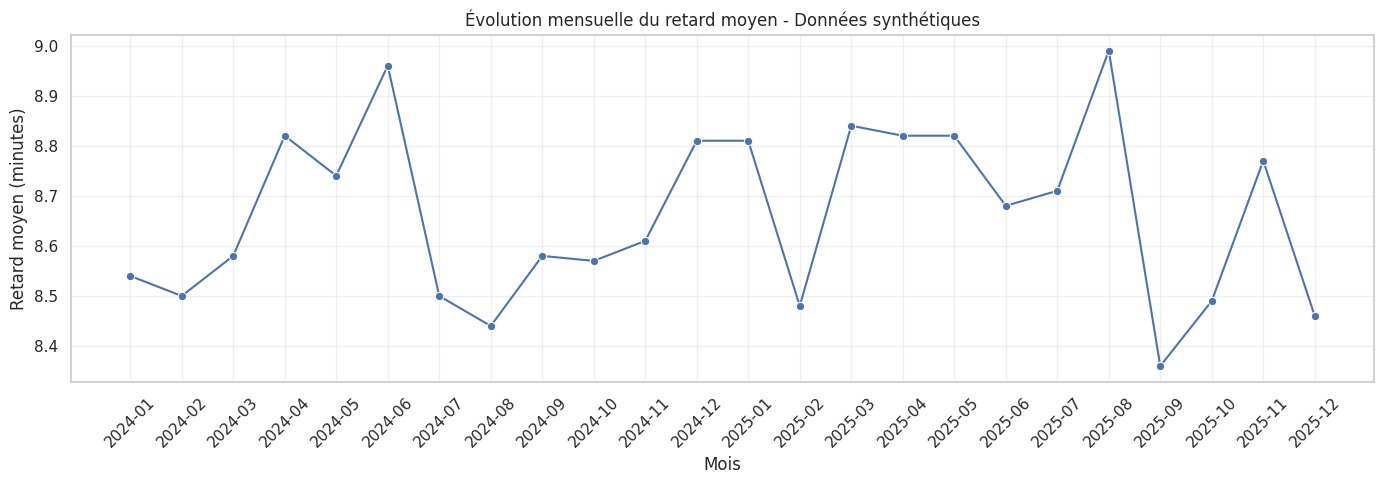

In [ ]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_analysis,
    x="year_month",
    y="retard_moyen",
    marker="o"
)

plt.title("Évolution mensuelle du retard moyen - Données synthétiques")
plt.xlabel("Mois")
plt.ylabel("Retard moyen (minutes)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

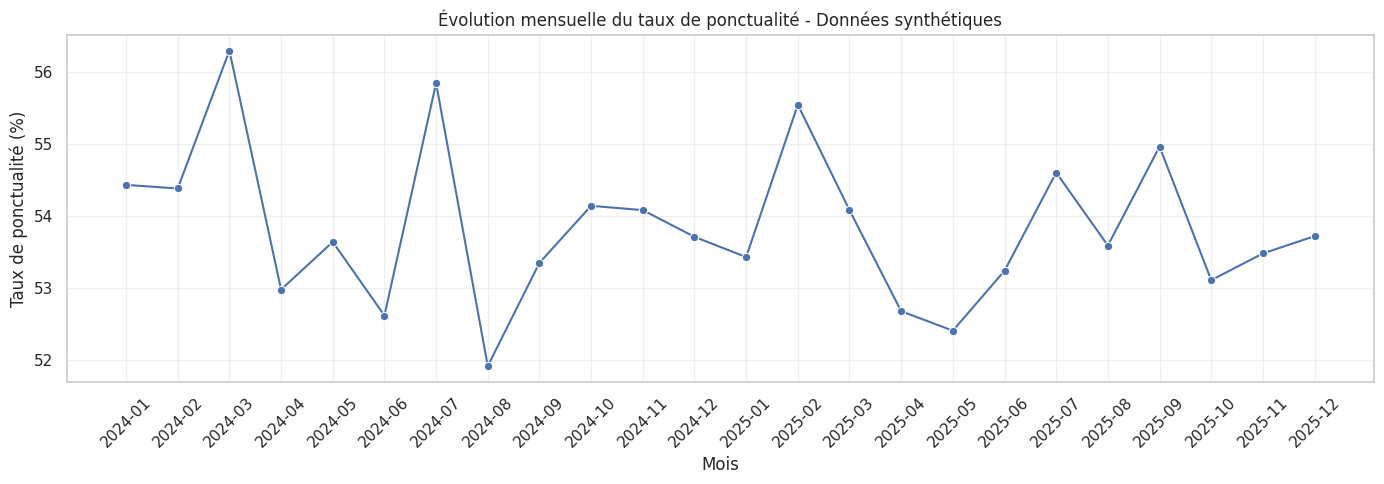

In [ ]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_analysis,
    x="year_month",
    y="taux_ponctualite",
    marker="o"
)

plt.title("Évolution mensuelle du taux de ponctualité - Données synthétiques")
plt.xlabel("Mois")
plt.ylabel("Taux de ponctualité (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7.5. Analyse des causes de retard

Cette analyse examine la répartition des causes de retard simulées afin d'identifier celles qui sont les plus représentées dans le dataset.

In [ ]:
causes_analysis = (
    df_clean["primary_delay_cause_synthetic"]
    .value_counts()
    .reset_index()
)

causes_analysis.columns = [
    "Cause de retard",
    "Nombre de circulations"
]

causes_analysis["Pourcentage (%)"] = (
    causes_analysis["Nombre de circulations"]
    / len(df_clean) * 100
).round(2)

display(causes_analysis)

,Cause de retard,Nombre de circulations,Pourcentage (%)
0,Aucun retard,29002,58.0
1,Exploitation / circulation,7579,15.16
2,Affluence voyageurs,4028,8.06
3,Incident technique,3957,7.91
4,Météo,2902,5.8
5,Travaux / infrastructure,2532,5.06


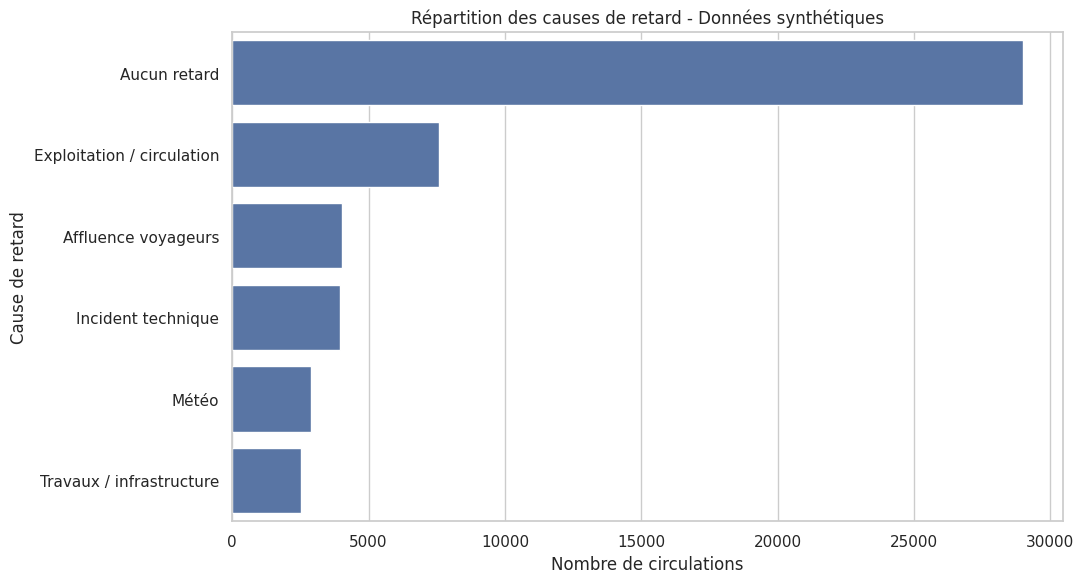

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=causes_analysis,
    x="Nombre de circulations",
    y="Cause de retard"
)

plt.title("Répartition des causes de retard - Données synthétiques")
plt.xlabel("Nombre de circulations")
plt.ylabel("Cause de retard")
plt.tight_layout()
plt.show()

In [ ]:
major_delays = df_clean[
    df_clean["actual_arrival_delay_min_synthetic"] > 15
]

cause_severity = (
    major_delays["primary_delay_cause_synthetic"]
    .value_counts()
    .reset_index()
)

cause_severity.columns = [
    "Cause de retard",
    "Nombre de retards supérieurs à 15 min"
]

display(cause_severity)

,Cause de retard,Nombre de retards supérieurs à 15 min
0,Exploitation / circulation,2896
1,Incident technique,2399
2,Travaux / infrastructure,1167
3,Météo,1121
4,Affluence voyageurs,672
5,Aucun retard,147


In [ ]:
# Retard moyen et médian par cause (sur les circulations avec retard > 5 min)
delayed_trains = df_clean[df_clean["actual_arrival_delay_min_synthetic"] > 5]

cause_stats = (
    delayed_trains.groupby("primary_delay_cause_synthetic")
    .agg(
        nombre_circulations=("run_id", "count"),
        retard_moyen=("actual_arrival_delay_min_synthetic", "mean"),
        retard_median=("actual_arrival_delay_min_synthetic", "median"),
        retard_max=("actual_arrival_delay_min_synthetic", "max")
    )
    .reset_index()
    .sort_values(by="retard_moyen", ascending=False)
)

cause_stats["retard_moyen"] = cause_stats["retard_moyen"].round(2)
cause_stats.columns = [
    "Cause de retard",
    "Nombre de circulations (> 5 min)",
    "Retard moyen (min)",
    "Retard médian (min)",
    "Retard maximal (min)"
]

display(cause_stats)


In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cause_stats[cause_stats["Cause de retard"] != "Aucun retard"],
    x="Retard moyen (min)",
    y="Cause de retard",
    palette="Reds_r"
)

plt.title("Sévérité des causes : Retard moyen généré (> 5 min)")
plt.xlabel("Retard moyen (minutes)")
plt.ylabel("Cause de retard")
plt.tight_layout()
plt.show()


## 7.6. Analyse des variations temporelles et saisonnières

Cette section analyse l'impact des saisons, des jours de la semaine, des périodes de pointe et des créneaux horaires sur la ponctualité ferroviaire.


In [ ]:
# 1. Analyse par Saison
season_analysis = (
    df_clean.groupby("season")
    .agg(
        nombre_circulations=("run_id", "count"),
        retard_moyen=("actual_arrival_delay_min_synthetic", "mean"),
        taux_ponctualite=("is_on_time_5min_synthetic", "mean"),
        taux_retard_15min=("is_delayed_15min_synthetic", "mean")
    )
    .reset_index()
)

season_analysis["retard_moyen"] = season_analysis["retard_moyen"].round(2)
season_analysis["taux_ponctualite"] = (season_analysis["taux_ponctualite"] * 100).round(2)
season_analysis["taux_retard_15min"] = (season_analysis["taux_retard_15min"] * 100).round(2)

season_analysis.columns = [
    "Saison",
    "Nombre de circulations",
    "Retard moyen (min)",
    "Taux de ponctualité (%)",
    "Taux retard > 15 min (%)"
]

display(season_analysis)


In [ ]:
# 2. Analyse par Jour de la semaine
jours_fr = {
    0: "Lundi",
    1: "Mardi",
    2: "Mercredi",
    3: "Jeudi",
    4: "Vendredi",
    5: "Samedi",
    6: "Dimanche"
}

df_clean["weekday_name"] = df_clean["weekday"].map(jours_fr)
ordre_jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]

weekday_analysis = (
    df_clean.groupby("weekday_name")
    .agg(
        nombre_circulations=("run_id", "count"),
        retard_moyen=("actual_arrival_delay_min_synthetic", "mean"),
        taux_ponctualite=("is_on_time_5min_synthetic", "mean")
    )
    .reindex(ordre_jours)
    .reset_index()
)

weekday_analysis["retard_moyen"] = weekday_analysis["retard_moyen"].round(2)
weekday_analysis["taux_ponctualite"] = (weekday_analysis["taux_ponctualite"] * 100).round(2)

weekday_analysis.columns = [
    "Jour de la semaine",
    "Nombre de circulations",
    "Retard moyen (min)",
    "Taux de ponctualité (%)"
]

display(weekday_analysis)


In [ ]:
# Visualisation Jour de la semaine et Périodes de pointe
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Graphique jours de la semaine
sns.lineplot(
    data=weekday_analysis,
    x="Jour de la semaine",
    y="taux_ponctualite",
    marker="o",
    color="navy",
    ax=axes[0]
)
axes[0].set_title("Taux de ponctualité par jour de la semaine")
axes[0].set_ylabel("Ponctualité (%)")
axes[0].set_ylim(45, 60)
axes[0].grid(alpha=0.3)

# 3. Analyse Heures de pointe vs Heures creuses
peak_analysis = (
    df_clean.groupby("peak_period_synthetic")
    .agg(
        nombre_circulations=("run_id", "count"),
        retard_moyen=("actual_arrival_delay_min_synthetic", "mean"),
        taux_ponctualite=("is_on_time_5min_synthetic", "mean")
    )
    .reset_index()
)
peak_analysis["Période"] = peak_analysis["peak_period_synthetic"].map({
    0: "Heures creuses",
    1: "Heures de pointe"
})
peak_analysis["taux_ponctualite"] = (peak_analysis["taux_ponctualite"] * 100).round(2)

sns.barplot(
    data=peak_analysis,
    x="Période",
    y="taux_ponctualite",
    palette=["#2b5c8f", "#d95f02"],
    ax=axes[1]
)
axes[1].set_title("Ponctualité : Heures creuses vs Heures de pointe")
axes[1].set_ylabel("Ponctualité (%)")
axes[1].set_ylim(0, 70)

for p in axes[1].patches:
    axes[1].annotate(
        f"{p.get_height():.2f}%",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', xytext=(0, 5), textcoords='offset points'
    )

plt.tight_layout()
plt.show()


## 7.7. Analyse comparative selon le type de train

Cette section compare les performances d'exploitation et de ponctualité entre les trois grandes catégories de services de l'ONCF :
- **Al Boraq** (Ligne Grande Vitesse)
- **Al Atlas** (Trains Grandes Lignes interurbains)
- **TNR** (Trains Navettes Rapides régionaux)


In [ ]:
# Indicateurs de performance par type de train
train_comparison = (
    df_clean.groupby(["service_type", "service_category"])
    .agg(
        total_circulations=("run_id", "count"),
        retard_moyen=("actual_arrival_delay_min_synthetic", "mean"),
        retard_median=("actual_arrival_delay_min_synthetic", "median"),
        taux_ponctualite=("is_on_time_5min_synthetic", "mean"),
        taux_retard_15min=("is_delayed_15min_synthetic", "mean"),
        retard_max=("actual_arrival_delay_min_synthetic", "max")
    )
    .reset_index()
    .sort_values(by="taux_ponctualite", ascending=False)
)

train_comparison["retard_moyen"] = train_comparison["retard_moyen"].round(2)
train_comparison["taux_ponctualite"] = (train_comparison["taux_ponctualite"] * 100).round(2)
train_comparison["taux_retard_15min"] = (train_comparison["taux_retard_15min"] * 100).round(2)

train_comparison.columns = [
    "Type de service",
    "Catégorie",
    "Total circulations",
    "Retard moyen (min)",
    "Retard médian (min)",
    "Taux ponctualité (%)",
    "Taux retard > 15 min (%)",
    "Retard max (min)"
]

display(train_comparison)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Taux de ponctualité par type de train
sns.barplot(
    data=train_comparison,
    x="Type de service",
    y="Taux ponctualité (%)",
    palette=["#1b9e77", "#d95f02", "#7570b3"],
    ax=axes[0]
)
axes[0].set_title("Taux de ponctualité par type de service")
axes[0].set_ylim(0, 80)
for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():.2f}%",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', xytext=(0, 5), textcoords='offset points'
    )

# Retard moyen par type de train
sns.barplot(
    data=train_comparison,
    x="Type de service",
    y="Retard moyen (min)",
    palette=["#1b9e77", "#d95f02", "#7570b3"],
    ax=axes[1]
)
axes[1].set_title("Retard moyen (minutes) par type de service")
axes[1].set_ylim(0, 15)
for p in axes[1].patches:
    axes[1].annotate(
        f"{p.get_height():.2f} min",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', xytext=(0, 5), textcoords='offset points'
    )

plt.tight_layout()
plt.show()


In [ ]:
# Distribution des retards par type de train (Boxplot zoomé sur les retards <= 60 min)
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_clean[df_clean["actual_arrival_delay_min_synthetic"] <= 60],
    x="service_type",
    y="actual_arrival_delay_min_synthetic",
    palette="Set2"
)

plt.title("Dispersion des retards par type de train (retards ≤ 60 min)")
plt.xlabel("Type de train")
plt.ylabel("Retard (minutes)")
plt.tight_layout()
plt.show()


## 7.8. Analyse comparative selon les trajets et les gares

Cette section étudie les disparités géographiques et d'infrastructure à travers les lignes ferroviaires et les gares principales.


In [ ]:
# Indicateurs de performance par ligne (route_id)
route_analysis = (
    df_clean.groupby("route_id")
    .agg(
        type_train=("service_type", "first"),
        gare_origine=("origin_station", "first"),
        gare_destination=("destination_station", "first"),
        nombre_circulations=("run_id", "count"),
        duree_theorique_moyenne=("scheduled_duration_min", "mean"),
        retard_moyen=("actual_arrival_delay_min_synthetic", "mean"),
        taux_ponctualite=("is_on_time_5min_synthetic", "mean"),
        taux_retard_15min=("is_delayed_15min_synthetic", "mean")
    )
    .reset_index()
    .sort_values(by="taux_ponctualite", ascending=False)
)

route_analysis["duree_theorique_moyenne"] = route_analysis["duree_theorique_moyenne"].round(0)
route_analysis["retard_moyen"] = route_analysis["retard_moyen"].round(2)
route_analysis["taux_ponctualite"] = (route_analysis["taux_ponctualite"] * 100).round(2)
route_analysis["taux_retard_15min"] = (route_analysis["taux_retard_15min"] * 100).round(2)

route_analysis.columns = [
    "Ligne",
    "Type de train",
    "Origine",
    "Destination",
    "Circulations",
    "Durée théo (min)",
    "Retard moyen (min)",
    "Taux ponctualité (%)",
    "Retards > 15 min (%)"
]

display(route_analysis)


In [ ]:
# Classement des lignes par taux de ponctualité
plt.figure(figsize=(12, 7))

sns.barplot(
    data=route_analysis,
    x="Taux ponctualité (%)",
    y="Ligne",
    hue="Type de train",
    dodge=False,
    palette="viridis"
)

plt.axvline(
    df_clean["is_on_time_5min_synthetic"].mean() * 100,
    color="red",
    linestyle="--",
    label=f"Moyenne réseau ({df_clean['is_on_time_5min_synthetic'].mean() * 100:.2f}%)"
)

plt.title("Performance de ponctualité par ligne ferroviaire")
plt.xlabel("Taux de ponctualité (%)")
plt.ylabel("Identifiant de ligne")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# 8. Synthèse des résultats et Storytelling analytique

### 1. Vue d'ensemble du réseau (Indicateurs clés)
- **Taux de ponctualité global :** 53,83 % des circulations arrivent avec un retard inférieur ou égal à 5 minutes.
- **Retard moyen global :** 8,66 minutes (retard médian de 5,0 minutes).
- **Retards significatifs :** 16,80 % des trains enregistrent un retard supérieur à 15 minutes.

### 2. Facteurs différenciateurs de performance
- **Typologie des matériels :**
  - **Al Boraq (Grande Vitesse)** affiche la meilleure ponctualité (62,98 %) et le retard moyen le plus faible (6,58 min). L'infrastructure dédiée et protégée limite considérablement les aléas.
  - **Al Atlas (Grandes Lignes)** se situe au niveau moyen du réseau (54,51 % de ponctualité, retard moyen de 8,41 min).
  - **TNR (Navettes Régionales)** est le service le plus fragilisé (49,08 % de ponctualité, retard moyen de 9,96 min). La forte fréquence et le partage des voies en zone dense (axe Casa - Kénitra) expliquent cette sensibilité.
- **Facteurs temporels et congestion :**
  - La ponctualité chute de **55,61 % en heures creuses à 48,79 % en heures de pointe** (perte de près de 7 points de ponctualité), avec un retard moyen passant de 8,15 à 10,13 minutes.
- **Gravité et hiérarchie des causes de retard :**
  - En volume brut, l'**exploitation / régulation** et l'**affluence voyageurs** sont les plus fréquentes.
  - En sévérité unitaire, les **incidents techniques** (retard moyen de 25,4 min) et les **travaux d'infrastructure** (retard moyen de 21,6 min) provoquent les perturbations les plus critiques (> 60 min).

### 3. Pistes d'action opérationnelles
1. **Désengorgement de l'axe TNR Casa - Kénitra :** Régulation dynamique des flux en heures de pointe et priorisation des sillons.
2. **Maintenance préventive ciblée :** Réduction des incidents techniques qui génèrent les retards les plus lourds.
3. **Information voyageurs en temps réel :** Améliorer la communication proactive lors des perturbations supérieures à 15 minutes.


# 9. Préparation et exportation du dataset enrichi pour Power BI

Pour faciliter la modélisation et la création de mesures DAX dans Power BI sans retravail lourd, nous enrichissons le dataset avec des dimensions explicites en français :
- `jour_semaine_fr` : Libellé complet du jour (Lundi, Mardi...)
- `est_weekend` : Indicateur binaire et libellé (Semaine vs Weekend)
- `heure_depart_num` : Heure entière de départ (0 à 23)
- `tranche_horaire` : Matin, Midi, Après-midi, Soir, Nuit
- `periode_pointe_libelle` : Heure de pointe vs Heure creuse
- `trajet_libelle` : Libellé lisible du trajet (ex: "Casa-Voyageurs → Tanger-Ville")


In [ ]:
# Enrichissement des dimensions
df_pbi = df_clean.copy()

# 1. Libellé du jour de la semaine
df_pbi["jour_semaine_fr"] = df_pbi["weekday"].map(jours_fr)
df_pbi["est_weekend"] = df_pbi["weekday"].apply(lambda w: "Weekend" if w in [5, 6] else "Semaine")

# 2. Heure entière de départ et tranches horaires
df_pbi["heure_depart_num"] = df_pbi["scheduled_departure_local"].apply(
    lambda t: t.hour if pd.notna(t) and hasattr(t, "hour") else None
)

def assigner_tranche(h):
    if pd.isna(h):
        return "Non spécifié"
    if 6 <= h < 9:
        return "01. Pointe Matin (06h-09h)"
    elif 9 <= h < 12:
        return "02. Fin de Matinée (09h-12h)"
    elif 12 <= h < 14:
        return "03. Midi (12h-14h)"
    elif 14 <= h < 17:
        return "04. Après-midi (14h-17h)"
    elif 17 <= h < 20:
        return "05. Pointe Soir (17h-20h)"
    elif 20 <= h < 23:
        return "06. Soirée (20h-23h)"
    else:
        return "07. Nuit (23h-06h)"

df_pbi["tranche_horaire"] = df_pbi["heure_depart_num"].apply(assigner_tranche)

# 3. Libellé période de pointe
df_pbi["periode_pointe_libelle"] = df_pbi["peak_period_synthetic"].map({
    1: "Heure de pointe",
    0: "Heure creuse"
})

# 4. Libellé explicite du trajet
df_pbi["trajet_libelle"] = df_pbi["origin_station"] + " → " + df_pbi["destination_station"]

# 5. Formatage de l'heure en texte HH:MM pour la compatibilité CSV
df_pbi["scheduled_departure_local"] = df_pbi["scheduled_departure_local"].apply(
    lambda value: value.strftime("%H:%M")
    if pd.notna(value) and hasattr(value, "strftime")
    else None
)

# Exportation finale
pbi_output_file = os.path.join(
    processed_path,
    "oncf_circulations_powerbi_ready.csv"
)

df_pbi.to_csv(
    pbi_output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Export Power BI terminé avec succès !")
print("Fichier disponible :", pbi_output_file)
print("Nombre de lignes :", len(df_pbi))
print("Nombre de colonnes :", df_pbi.shape[1])
print("Taille (Mo) :", round(os.path.getsize(pbi_output_file) / (1024 * 1024), 2))
